<a href="https://colab.research.google.com/github/ROHAN-BIT001/Heart_Failure_Boosting_Project/blob/main/Heart_Failure_Boosting_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Minor Project: Boosting
## Heart Failure Survival Prediction using Gradient Boosting

**Name:** Rohan Jha

**Dataset link:** https://archive.ics.uci.edu/dataset/519/heart+failure+clinical+records

**Short dataset description:** The dataset has medical records of 299 heart failure patients. It includes details like age, anaemia, diabetes, blood pressure, ejection fraction, serum creatinine and serum sodium. The last column, `DEATH_EVENT`, tells whether the patient died during the follow-up period (1) or survived (0).

## 1. Problem Statement and Objective

**Problem:** Predict whether a heart failure patient will die during the follow-up period using their clinical records.

**Why it matters:** Heart failure is a serious condition. If a model can find high-risk patients early, doctors can give them closer monitoring and faster treatment.

**Objective:** Build a Gradient Boosting classification model to predict `DEATH_EVENT` and find which medical factors matter most.

## 2. Load the Dataset

In [1]:
!pip install ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
heart_failure_clinical_records = fetch_ucirepo(id=519)

# data (as pandas dataframes)
X = heart_failure_clinical_records.data.features
y = heart_failure_clinical_records.data.targets

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.concat([X, y], axis = 1)
df.columns = df.columns.str.lower()   # make all column names lowercase
df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,death_event
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


## 3. Understand the Data

In [5]:
df.shape

(299, 13)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  death_event               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB


In [7]:
df.describe()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,death_event
count,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.00000,299.000000,299.000000,299.00000,299.000000,299.00000
mean,60.833893,0.431438,581.839465,0.418060,38.083612,0.351171,263358.029264,1.39388,136.625418,0.648829,0.32107,130.260870,0.32107
std,11.894809,0.496107,970.287881,0.494067,11.834841,0.478136,97804.236869,1.03451,4.412477,0.478136,0.46767,77.614208,0.46767
min,40.000000,0.000000,23.000000,0.000000,14.000000,0.000000,25100.000000,0.50000,113.000000,0.000000,0.00000,4.000000,0.00000
25%,51.000000,0.000000,116.500000,0.000000,30.000000,0.000000,212500.000000,0.90000,134.000000,0.000000,0.00000,73.000000,0.00000
50%,60.000000,0.000000,250.000000,0.000000,38.000000,0.000000,262000.000000,1.10000,137.000000,1.000000,0.00000,115.000000,0.00000
75%,70.000000,1.000000,582.000000,1.000000,45.000000,1.000000,303500.000000,1.40000,140.000000,1.000000,1.00000,203.000000,1.00000
max,95.000000,1.000000,7861.000000,1.000000,80.000000,1.000000,850000.000000,9.40000,148.000000,1.000000,1.00000,285.000000,1.00000


**Understanding of the data**
- **Rows:** each row is one heart failure patient (299 patients).
- **Columns:** `age`, `anaemia`, `creatinine_phosphokinase`, `diabetes`, `ejection_fraction`, `high_blood_pressure`, `platelets`, `serum_creatinine`, `serum_sodium`, `sex`, `smoking`, `time` and `death_event`.
- **Target variable:** `death_event` (1 = patient died, 0 = patient survived).
- **Binary columns (0/1):** `anaemia`, `diabetes`, `high_blood_pressure`, `sex`, `smoking`.
- **Important features:** age, ejection fraction (how much blood the heart pumps out), serum creatinine (kidney health), serum sodium and follow-up `time` (days).

## 4. Check Data Quality

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.isnull().sum()

,0
age,0
anaemia,0
creatinine_phosphokinase,0
diabetes,0
ejection_fraction,0
high_blood_pressure,0
platelets,0
serum_creatinine,0
serum_sodium,0
sex,0


In [10]:
df.dtypes

,0
age,float64
anaemia,int64
creatinine_phosphokinase,int64
diabetes,int64
ejection_fraction,int64
high_blood_pressure,int64
platelets,float64
serum_creatinine,float64
serum_sodium,int64
sex,int64


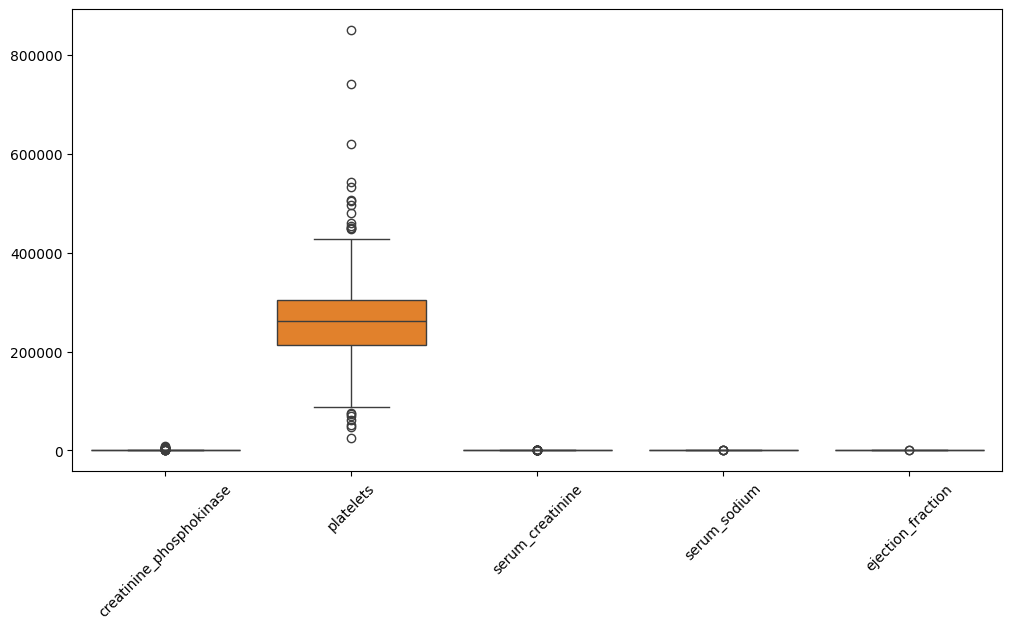

In [11]:
plt.figure(figsize = (12,6))
sns.boxplot(data = df[['creatinine_phosphokinase', 'platelets', 'serum_creatinine', 'serum_sodium', 'ejection_fraction']])
plt.xticks(rotation = 45)
plt.show()

In [12]:
df['death_event'].value_counts(normalize = True) * 100

,proportion
death_event,
0,67.892977
1,32.107023


**Data quality findings**
- No missing values and no duplicate rows.
- Data types are correct. All columns are numbers, and the 0/1 columns are already encoded, so no encoding is needed.
- `creatinine_phosphokinase`, `platelets` and `serum_creatinine` have many extreme values (outliers).
- The target is a bit imbalanced: about 68% survived and 32% died, which is not severe.

## 5. Prepare the Data (Cleaning)

In [13]:
# Outlier treatment using the IQR method
columns = ['creatinine_phosphokinase', 'platelets', 'serum_creatinine']
for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df[col] = np.where(df[col] > upper_limit, upper_limit, np.where(df[col] < lower_limit, lower_limit, df[col]))

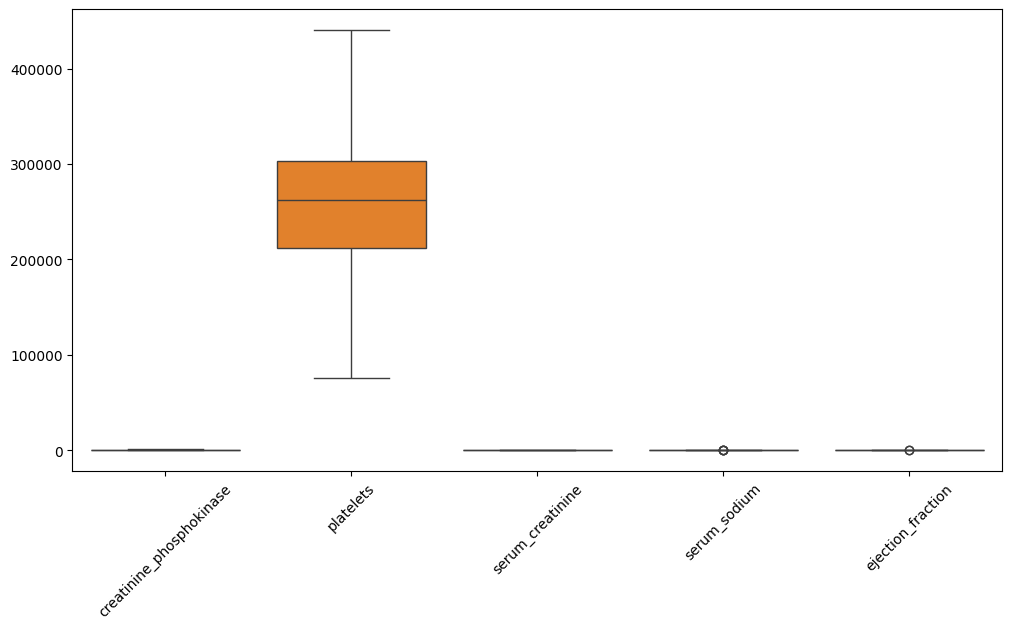

In [14]:
plt.figure(figsize = (12,6))
sns.boxplot(data = df[['creatinine_phosphokinase', 'platelets', 'serum_creatinine', 'serum_sodium', 'ejection_fraction']])
plt.xticks(rotation = 45)
plt.show()

**Data-cleaning summary**
1. Checked missing values and duplicates. None were found, so no rows were removed.
2. Confirmed all data types are numeric, so no conversion was needed.
3. Capped the outliers of `creatinine_phosphokinase`, `platelets` and `serum_creatinine` using the IQR method. Capping keeps all 299 rows, which matters because the dataset is small and we cannot afford to delete patients.
4. Did not treat `serum_sodium` and `ejection_fraction` because they have very few outliers.
5. Did not scale or encode any column because boosting uses decision trees, which do not need scaling.

## 6. Explore and Visualize

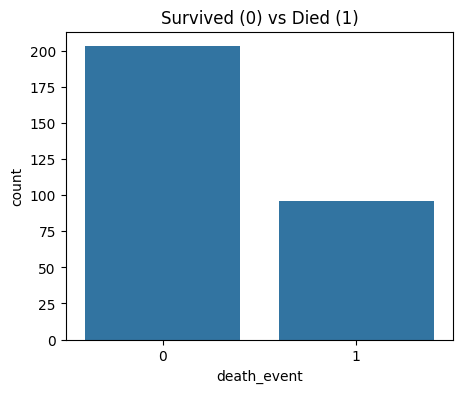

In [15]:
plt.figure(figsize = (5,4))
sns.countplot(x = 'death_event', data = df)
plt.title('Survived (0) vs Died (1)')
plt.show()

**Observation 1:** Out of 299 patients, 96 died (about 32%) and 203 survived. The classes are a little imbalanced, but not enough to need any special technique.

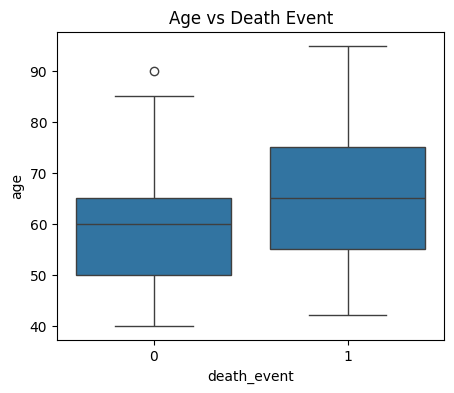

In [16]:
plt.figure(figsize = (5,4))
sns.boxplot(x = 'death_event', y = 'age', data = df)
plt.title('Age vs Death Event')
plt.show()

**Observation 2:** Patients who died are older. The median age is about 65 for patients who died and about 60 for those who survived, so age is a risk factor.

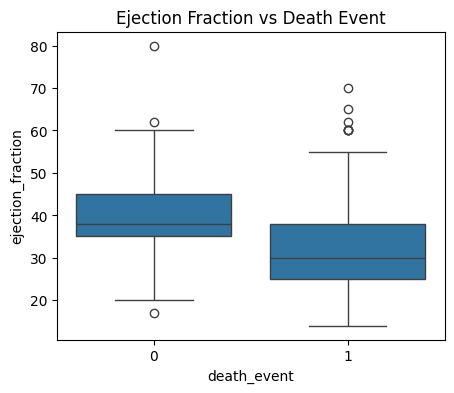

In [17]:
plt.figure(figsize = (5,4))
sns.boxplot(x = 'death_event', y = 'ejection_fraction', data = df)
plt.title('Ejection Fraction vs Death Event')
plt.show()

**Observation 3:** Patients who died have a lower ejection fraction (median about 30%) than survivors (median about 38%). A weaker heart pump goes with a higher chance of death.

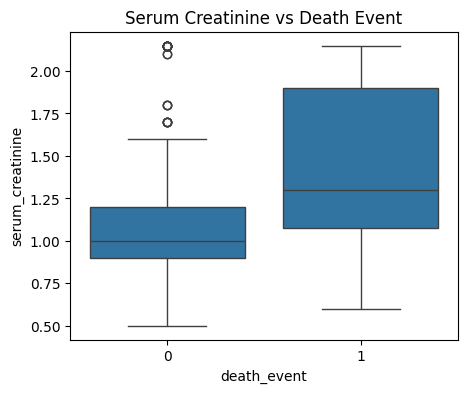

In [18]:
plt.figure(figsize = (5,4))
sns.boxplot(x = 'death_event', y = 'serum_creatinine', data = df)
plt.title('Serum Creatinine vs Death Event')
plt.show()

**Observation 4:** Patients who died have higher serum creatinine (median about 1.3 versus about 1.0), which points to poorer kidney function in patients at higher risk.

## 7. Choose the Approach

This is a **binary classification** problem (died = 1, survived = 0).

**Why Gradient Boosting?** Boosting builds many small decision trees one after another, and each new tree tries to fix the mistakes of the previous trees. It usually works better than a single tree on tabular data like this, and it does not need scaling of the features.

**Why no SMOTE?** The classes are 68% / 32%, which is not very imbalanced, and the dataset is already small, so I did not create synthetic data.

## 8. Build the Model

In [19]:
X = df.drop('death_event', axis = 1)
y = df['death_event']

In [20]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

print(y_train.value_counts())
print(y_test.value_counts())

death_event
0    162
1     77
Name: count, dtype: int64
death_event
0    41
1    19
Name: count, dtype: int64


In [21]:
from sklearn.ensemble import GradientBoostingClassifier
model = GradientBoostingClassifier(random_state = 42)
model.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

## 9. Evaluate the Model

In [22]:
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, model.predict_proba(X_test)[:,1]))

              precision    recall  f1-score   support

           0       0.84      0.90      0.87        41
           1       0.75      0.63      0.69        19

    accuracy                           0.82        60
   macro avg       0.80      0.77      0.78        60
weighted avg       0.81      0.82      0.81        60

Accuracy: 0.8166666666666667
ROC AUC: 0.8356867779204107


In [23]:
# Most important features
importance = pd.Series(model.feature_importances_, index = X.columns).sort_values(ascending = False)
importance.head(5)

,0
time,0.607042
serum_creatinine,0.113609
ejection_fraction,0.107969
platelets,0.072523
creatinine_phosphokinase,0.034940


**What the results mean (in simple language)**
- **Accuracy (about 82%):** the model predicted the correct outcome for about 8 out of every 10 patients in the test set.
- **Recall for class 1 (about 0.63):** out of all patients who actually died, the model caught about 63%. This is the most important number here, because missing a high-risk patient is the worst mistake.
- **Precision for class 1 (about 0.75):** when the model says a patient will die, it is right about 75% of the time.
- **ROC AUC (about 0.84):** the model separates patients who died from those who survived much better than random guessing (0.5).
- **Feature importance:** `time` is the most important feature by a big margin, followed by `serum_creatinine` and `ejection_fraction`. This matches what we saw in the charts.


## 10. Conclusion

**Key findings:** Older age, lower ejection fraction and higher serum creatinine are linked with a higher chance of death in heart failure patients. The Gradient Boosting model predicted survival correctly for about 82% of test patients, with a ROC AUC of about 0.84.

**Limitations:**
- Only 299 patients, and the test set has just 60, so the results can change a lot with a different split.
- The model misses about 4 out of 10 patients who actually died, which is too many for real medical use.
- `time` (follow-up days) is the strongest feature, but this value is only known after the follow-up, not when a patient is first diagnosed. This makes the model look better than it would be for early prediction.
- The data comes from one hospital, so it may not work for other patients.

**Future improvements:** Remove `time` to build a model that predicts from admission details only, tune the hyperparameters, use cross-validation for a more stable result, compare with other boosting models like XGBoost or CatBoost, and try to improve recall for deaths.